<a href="https://colab.research.google.com/github/ubexplorer/g-colab/blob/main/bonds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

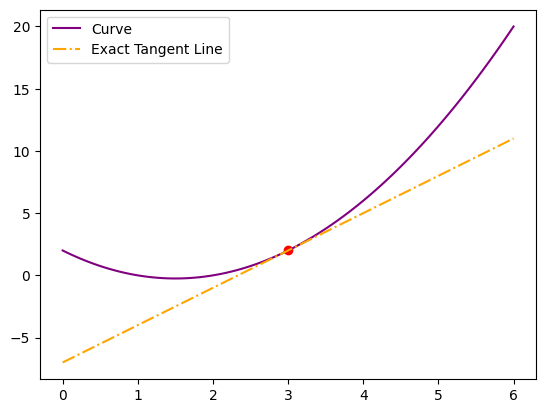

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# Step 1: Define symbol and the expression symbolically
x = sp.Symbol('x')
f_expr = x**2 - 3*x + 2  # Example: x² - 3x + 2

# Step 2: Differentiate to find the exact slope equation
f_prime_expr = sp.diff(f_expr, x)

# Step 3: Turn SymPy expressions into fast NumPy functions
f = sp.lambdify(x, f_expr, 'numpy')
f_prime = sp.lambdify(x, f_prime_expr, 'numpy')

# Step 4: Set up coordinates
x_val = 3.0  # Tangent point
y_val = f(x_val)
slope = f_prime(x_val)

# Step 5: Generate plot arrays
x_arr = np.linspace(0, 6, 100)
y_tangent = slope * (x_arr - x_val) + y_val

# Step 6: Render the plot
plt.plot(x_arr, f(x_arr), label="Curve", color="purple")
plt.plot(x_arr, y_tangent, label="Exact Tangent Line", color="orange", linestyle="-.")
plt.scatter(x_val, y_val, color="red")
plt.legend()
plt.show()

In [1]:
## ql zero bond

In [7]:
!pip install quantlib
import QuantLib as ql

# 1. Налаштування дат (наприклад, купівля 12 жовтня 2026, погашення через рік)
calendar = ql.Ukraine()
today = ql.Date(12, 10, 2026)
ql.Settings.instance().evaluationDate = today

settlement_days = 0  # розрахунки "сьогодні в день угоди"
settlement_date = calendar.advance(today, settlement_days, ql.Days)
maturity_date = ql.Date(12, 10, 2027)

# 2. Параметри облігації
face_amount = 1000.0       # Номінал однієї ОВДП (1000 грн)
redemption_value = 100.0   # Сума погашення у % від номіналу
day_counter = ql.Actual365Fixed()  # Стандартна конвенція для ОВДП

# Створення безкупонної облігації (Zero Coupon Bond)
bond = ql.ZeroCouponBond(
    settlement_days,
    calendar,
    face_amount,
    maturity_date,
    ql.Following,
    redemption_value,
    settlement_date
)

# 3. Задання ставки дохідності та розрахунок ціни
yield_rate = 0.2  # Дохідність 15% (0.15)

# Варіант А: Розрахунок за конвенцією простих відсотків (Simple)
# Формула: Price = Redemption / (1 + r * T)
price_simple = bond.cleanPrice(
    yield_rate,
    day_counter,
    ql.Simple,
    ql.Annual,
    settlement_date
)

# Варіант Б: Розрахунок за конвенцією складних відсотків (Compounded)
# Формула: Price = Redemption / (1 + r)^T
price_compounded = bond.cleanPrice(
    yield_rate,
    day_counter,
    ql.Compounded,
    ql.Annual,
    settlement_date
)

print(f"Чиста ціна (% від номіналу, прості відсотки): {price_simple:.4f}%")
print(f"Вартість однієї ОВДП: {face_amount * price_simple / 100:.2f} грн\n")

print(f"Чиста ціна (% від номіналу, складні відсотки): {price_compounded:.4f}%")
print(f"Вартість однієї ОВДП: {face_amount * price_compounded / 100:.2f} грн")

Чиста ціна (% від номіналу, прості відсотки): 83.3333%
Вартість однієї ОВДП: 833.33 грн

Чиста ціна (% від номіналу, складні відсотки): 83.3333%
Вартість однієї ОВДП: 833.33 грн
